# Module 3: Centrality Measures

In [1]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt

In [2]:
G_jazz = nx.read_gml("dataset/graph_jazz_collab.gml")

print(G_jazz)
print("Directed:  ", G_jazz.is_directed())
print("Multigraph:", G_jazz.is_multigraph())
print("Self-loops:", nx.number_of_selfloops(G_jazz))
print("Connected: ", nx.is_connected(G_jazz))
print("Components:", nx.number_connected_components(G_jazz))

Graph with 198 nodes and 2742 edges
Directed:   False
Multigraph: False
Self-loops: 0
Connected:  True
Components: 1


## Question 1
Degree, closeness, betweenness and eigenvector centrality for every node.

In [3]:
deg_c = nx.degree_centrality(G_jazz)
clo_c = nx.closeness_centrality(G_jazz)
bet_c = nx.betweenness_centrality(G_jazz)
eig_c = nx.eigenvector_centrality(G_jazz, max_iter=1000)

In [4]:
for name, c in [("Degree", deg_c), ("Closeness", clo_c),
                ("Betweenness", bet_c), ("Eigenvector", eig_c)]:
    top5 = sorted(c, key=c.get, reverse=True)[:5]
    print(f"{name:12s}", top5)

Degree       ['28', '6', '19', '22', '60']
Closeness    ['28', '6', '22', '60', '62']
Betweenness  ['28', '107', '6', '103', '22']
Eigenvector  ['6', '19', '28', '22', '17']


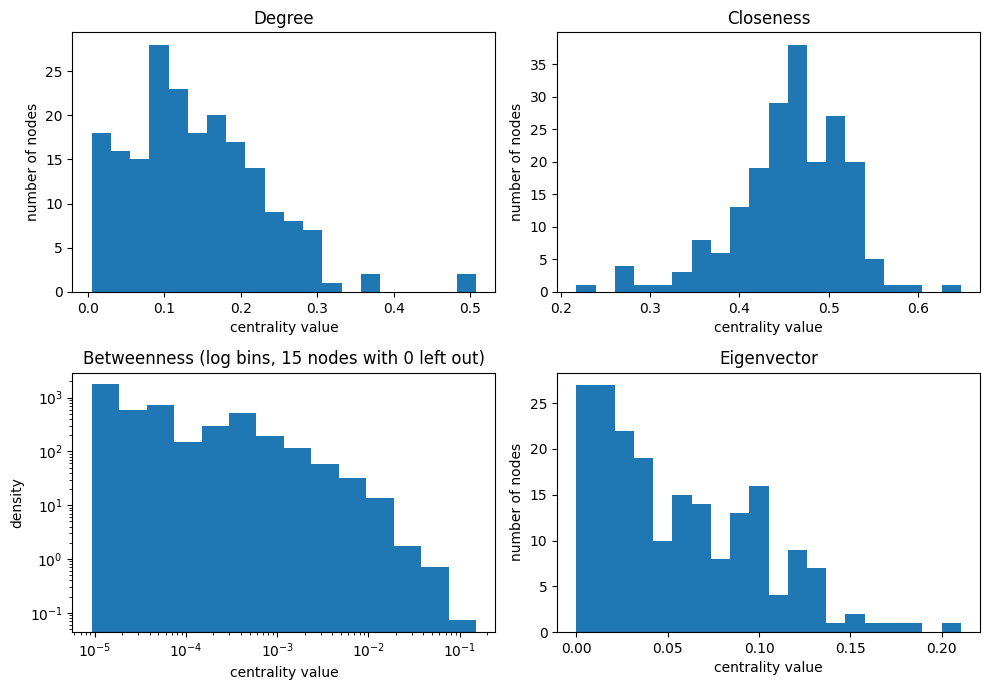

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))

for ax, (name, c) in zip(axes.flat, cents.items()):
    values = np.array(list(c.values()))

    if name == "Betweenness":
        positive = values[values > 0]                       # log axes can't show 0
        bins = np.logspace(np.log10(positive.min()), np.log10(positive.max()), 15)
        ax.hist(positive, bins=bins, density=True)
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_ylabel("density")
        ax.set_title(f"{name} (log bins, {np.sum(values == 0)} nodes with 0 left out)")
    else:
        ax.hist(values, bins=20)
        ax.set_ylabel("number of nodes")
        ax.set_title(name)

    ax.set_xlabel("centrality value")

plt.tight_layout()
plt.show()

**Choice of bins and scales.** Degree, closeness and eigenvector centrality are spread over a 
limited range without an extreme tail, so linear bins and axes are used. Betweenness is strongly 
skewed: most musicians lie on almost no shortest paths, while a few bridge nodes have very high 
values. It is therefore shown with logarithmic bins and log–log axes (normalised by bin width). 
Nodes with betweenness exactly 0 cannot be shown on a log axis and are left out; their number 
is given in the title.

## Question 2
Pair of centralities.

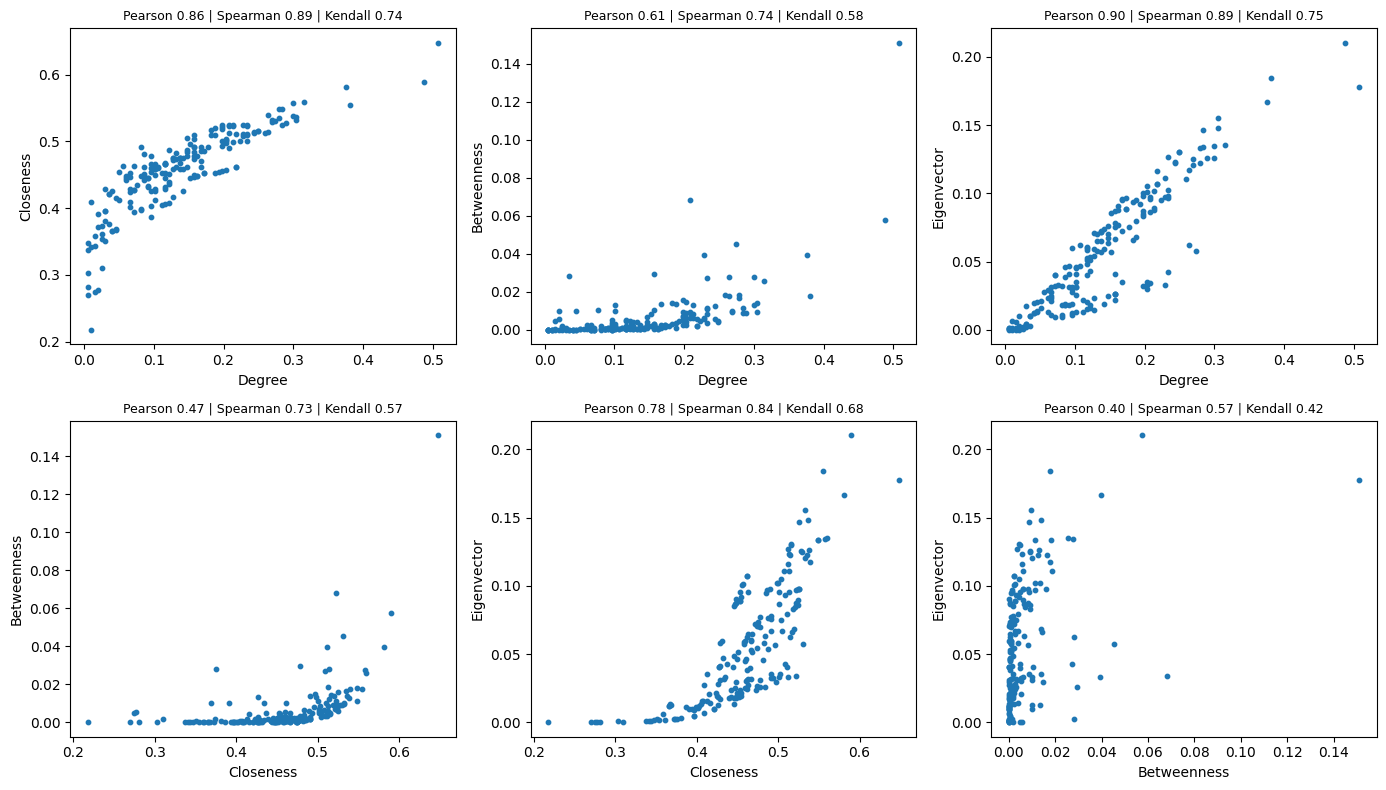

In [8]:
from scipy import stats

# Same node order for every measure
nodes = list(G_jazz.nodes())
vals = {name: np.array([c[n] for n in nodes]) for name, c in cents.items()}

pairs = [("Degree", "Closeness"), ("Degree", "Betweenness"), ("Degree", "Eigenvector"),
         ("Closeness", "Betweenness"), ("Closeness", "Eigenvector"), ("Betweenness", "Eigenvector")]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))

for ax, (a, b) in zip(axes.flat, pairs):
    x, y = vals[a], vals[b]
    pear  = stats.pearsonr(x, y)[0]
    spear = stats.spearmanr(x, y)[0]
    kend  = stats.kendalltau(x, y)[0]

    ax.scatter(x, y, s=10)
    ax.set_xlabel(a)
    ax.set_ylabel(b)
    ax.set_title(f"Pearson {pear:.2f} | Spearman {spear:.2f} | Kendall {kend:.2f}", fontsize=9)

plt.tight_layout()
plt.show()

**Results.** The Pearson coefficients agree with Lecture 3, slide 41. All pairs are positively 
correlated, but not perfectly:

- *Degree, closeness and eigenvector* agree strongly ($\rho \approx 0.84$–$0.89$).
- *Betweenness* agrees least with the others. Its Spearman values are clearly higher than its 
  Pearson values (e.g. closeness–betweenness: $r = 0.47$, $\rho = 0.73$): betweenness is highly 
  skewed and its relation to the other measures is curved, so the *rankings* agree better than a 
  straight line suggests.
- *Degree–eigenvector* shows two branches: musicians with the same number of collaborators can 
  have very different eigenvector centrality, depending on whether their collaborators are 
  themselves central.
- *Betweenness–eigenvector* shows many musicians with high eigenvector centrality but betweenness 
  near 0. They sit inside densely connected groups (bands are cliques), where no shortest path 
  needs to pass through them.

Kendall's $\tau$ is systematically smaller than Spearman's $\rho$, as expected for this 
coefficient; it confirms the same ordering of the pairs.

In [9]:
def randomise(G, niter=2, seed=42):
    return nx.algorithms.smallworld.random_reference(
        G.copy(), niter=niter, connectivity=False, seed=seed)

def compute_centralities(G):
    return {
        "Degree":      nx.degree_centrality(G),
        "Closeness":   nx.closeness_centrality(G),
        "Betweenness": nx.betweenness_centrality(G),
        "Eigenvector": nx.eigenvector_centrality(G, max_iter=1000),
    }

G_jazz_rand = randomise(G_jazz)

print(G_jazz_rand)
print("Degrees preserved:", dict(G_jazz.degree()) == dict(G_jazz_rand.degree()))
print("Connected:", nx.is_connected(G_jazz_rand))

cents_rand = compute_centralities(G_jazz_rand)

Graph with 198 nodes and 2742 edges
Degrees preserved: True
Connected: True


## Question 3
Randomization and comparison.

In [10]:
def randomise(G, niter=2, seed=42):
    return nx.algorithms.smallworld.random_reference(
        G.copy(), niter=niter, connectivity=False, seed=seed)

def compute_centralities(G):
    return {
        "Degree":      nx.degree_centrality(G),
        "Closeness":   nx.closeness_centrality(G),
        "Betweenness": nx.betweenness_centrality(G),
        "Eigenvector": nx.eigenvector_centrality(G, max_iter=1000),
    }

G_jazz_rand = randomise(G_jazz)

print(G_jazz_rand)
print("Degrees preserved:", dict(G_jazz.degree()) == dict(G_jazz_rand.degree()))
print("Connected:", nx.is_connected(G_jazz_rand))

cents_rand = compute_centralities(G_jazz_rand)

Graph with 198 nodes and 2742 edges
Degrees preserved: True
Connected: True


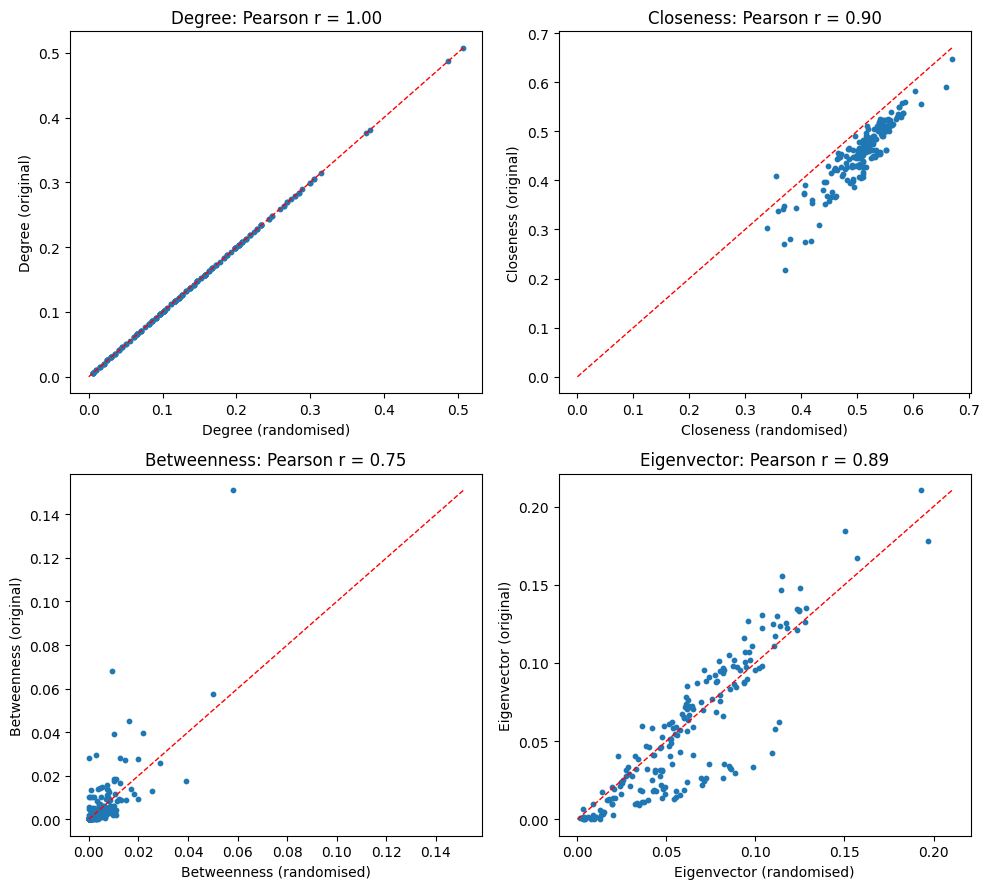

In [11]:
names = ["Degree", "Closeness", "Betweenness", "Eigenvector"]

fig, axes = plt.subplots(2, 2, figsize=(10, 9))

for ax, name in zip(axes.flat, names):
    orig = np.array([cents[name][n] for n in nodes])
    rand = np.array([cents_rand[name][n] for n in nodes])

    r = stats.pearsonr(rand, orig)[0]

    ax.scatter(rand, orig, s=10)
    lim = max(orig.max(), rand.max())
    ax.plot([0, lim], [0, lim], "r--", lw=1)

    ax.set_xlabel(f"{name} (randomised)")
    ax.set_ylabel(f"{name} (original)")
    ax.set_title(f"{name}: Pearson r = {r:.2f}")

plt.tight_layout()
plt.show()

### Q3 – Original vs. degree-preserving randomised centralities (jazz)

| Measure | Pearson r |
|---|---|
| Degree | 1.00 |
| Closeness | 0.90 |
| Betweenness | 0.75 |
| Eigenvector | 0.89 |

- **Degree** is unchanged (r = 1) because the edge swaps preserve every node's degree. It is a purely local measure.
- **Closeness**: the ranking is largely preserved, but almost all nodes have *lower* closeness in the original network. The real network is organised in dense groups (bands), so many edges are "used up" inside groups; randomisation creates shortcuts between groups and shortens distances.
- **Betweenness** changes most (lowest r). A few nodes (e.g. the top node, ≈0.15 originally vs ≈0.06 randomised) are bridges between groups in the real network. In the randomised network there are no groups, shortest paths are spread over many alternatives, and betweenness mostly follows degree.
- **Eigenvector**: nodes in the dense core gain importance in the original network (above the diagonal), while a group of nodes with moderate degree outside the core loses importance (below the diagonal). This is the second branch already seen in the Degree–Eigenvector plot of Q2.
- **Conclusion:** degree is fully explained by the degree sequence, while closeness, betweenness and eigenvector centrality also depend on the actual wiring (group structure). Betweenness is the most sensitive to it. This matches the lecture example (slide 44).
- Note: results are from a single randomisation (seed = 42).

### Q4 – Interpretation (jazz)

**Network:** nodes = jazz musicians, edges = played in the same band (1912–1940). Each band forms a clique.

**(a) Meaning of each centrality**
- **Degree:** number of different musicians someone played with. High = played in many and/or large bands. Partly reflects band size, since one large band gives many links at once.
- **Closeness:** how few collaboration steps separate a musician from everyone else. High = located in the centre of the scene, where information or styles can reach them quickly.
- **Betweenness:** how often a musician lies on shortest paths between others. High = broker who connects otherwise separate groups of musicians. Betweenness 0 = all collaborators also played with each other (only active in one closed group).
- **Eigenvector:** being connected to other well-connected musicians. High = member of the dense core of the scene ("prestige"). Musicians with many collaborators in a peripheral group score lower.

**(b) Similarities and differences among rankings**
- **Similarities:** musicians 28, 6 and 22 appear in the top 5 of all four measures, so they are central in every sense (many collaborators, core members and bridges). All correlations are positive, and degree, closeness and eigenvector centrality are strongly correlated (Pearson 0.78–0.90): having many collaborators goes together with being close to everyone and being part of the core.
- **Differences:** betweenness is the most distinct measure (weakest correlations). Musicians 107 and 103 are in the betweenness top 5 but not in any other top 5: they are bridges between groups despite a modest number of collaborators. Betweenness and eigenvector correlate least (Pearson 0.40) because they reward opposite positions: being between groups vs. being inside the dense core.
- **Pearson vs. Spearman:** for pairs involving betweenness, Spearman is clearly higher than Pearson (e.g. closeness–betweenness 0.47 vs 0.73). Betweenness is highly skewed, so Pearson is driven by a few extreme values, while the rankings agree more.

**(c) What the null-model comparison adds**
- The correlations in (b) alone cannot tell whether the measures agree because of the specific structure of the jazz network or simply because of the degrees. The degree-preserving null model separates the two.
- Closeness (r = 0.90) and eigenvector centrality (r = 0.89) remain highly correlated with their randomised versions, so a large part of them is already explained by degree. Part of the strong agreement in (b) is therefore a degree effect.
- Since r < 1, the actual wiring also matters: closeness is systematically lower in the real network (longer distances due to the band/group structure), and eigenvector centrality separates a dense core (above the diagonal) from peripheral groups (below).
- Betweenness changes most (r = 0.75): the bridging roles of a few musicians are genuine structural features that do not appear in a random network with the same degrees.

In [12]:
def ranks(c):
    order = sorted(c, key=c.get, reverse=True)
    return {node: i + 1 for i, node in enumerate(order)}

rank = {name: ranks(c) for name, c in cents.items()}

diff = {n: rank["Eigenvector"][n] - rank["Betweenness"][n] for n in nodes}
order = sorted(diff, key=diff.get)

print("Much better in EIGENVECTOR than betweenness (core members?):")
for n in order[:3]:
    print(n, "| degree", G_jazz.degree(n), {name: rank[name][n] for name in names})

print("\nMuch better in BETWEENNESS than eigenvector (bridges?):")
for n in order[-3:]:
    print(n, "| degree", G_jazz.degree(n), {name: rank[name][n] for name in names})

Much better in EIGENVECTOR than betweenness (core members?):
43 | degree 32 {'Degree': 70, 'Closeness': 125, 'Betweenness': 162, 'Eigenvector': 46}
186 | degree 19 {'Degree': 136, 'Closeness': 91, 'Betweenness': 192, 'Eigenvector': 82}
42 | degree 31 {'Degree': 73, 'Closeness': 130, 'Betweenness': 158, 'Eigenvector': 52}

Much better in BETWEENNESS than eigenvector (bridges?):
151 | degree 20 {'Degree': 126, 'Closeness': 152, 'Betweenness': 24, 'Eigenvector': 164}
190 | degree 4 {'Degree': 187, 'Closeness': 174, 'Betweenness': 34, 'Eigenvector': 174}
106 | degree 7 {'Degree': 173, 'Closeness': 177, 'Betweenness': 8, 'Eigenvector': 182}
